# Job Listings Scraper & Analysis

This notebook demonstrates the analysis of remote job listings collected from the Himalayas public Jobs API.

The project workflow is:

1. Collect job listings using the Python API scraper
2. Store the collected data in a CSV file
3. Store structured data in a SQLite database
4. Analyze the data using Pandas and SQL
5. Visualize key job market insights using Matplotlib

In [25]:
#Load Job Listings Dataset
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("jobs.csv")

df.head()

,title,company,employment_type,seniority,location,categories,min_salary,max_salary,salary_period,currency,date_posted,application_link,job_id
0,Provider Engagement Professional - Behavioral ...,Humana,Full Time,Mid-level,United States,"Provider-Relations, Healthcare-Administration,...",59300.0,80900.0,annual,USD,2026-09-07 15:37:14,https://himalayas.app/companies/humana/jobs/pr...,https://himalayas.app/companies/humana/jobs/pr...
1,Sr IT Engineer VDI,OhioHealth,Full Time,Senior,United States,"VDI-Engineer, IT-Infrastructure-Engineering, S...",NaN,NaN,annual,NaN,2026-09-07 15:36:38,https://himalayas.app/companies/ohiohealth/job...,https://himalayas.app/companies/ohiohealth/job...
2,Senior Business Solutions Analyst - CLO,UMB Bank,Full Time,Senior,United States,"Business-Analysis, CLO-Operations, Financial-S...",117900.0,173393.0,annual,USD,2026-09-07 15:36:01,https://himalayas.app/companies/umb-bank/jobs/...,https://himalayas.app/companies/umb-bank/jobs/...
3,Healthcare Claim Processor,Qualfon,Full Time,Mid-level,United States,"Healthcare-Claims-Processing, Medi-Cal-Claims-...",24.0,24.0,hourly,USD,2026-09-07 15:35:37,https://himalayas.app/companies/qualfon/jobs/h...,https://himalayas.app/companies/qualfon/jobs/h...
4,Substation Civil Site Designer,Leidos,Full Time,Mid-level,United States,"Substation-Civil-Designer, Civil-Site-Designer...",48100.0,86950.0,annual,USD,2026-09-07 15:34:29,https://himalayas.app/companies/leidos/jobs/su...,https://himalayas.app/companies/leidos/jobs/su...


In [26]:
#Dataset Overview and Missing Values
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (500, 13)

Column Names:
['title', 'company', 'employment_type', 'seniority', 'location', 'categories', 'min_salary', 'max_salary', 'salary_period', 'currency', 'date_posted', 'application_link', 'job_id']

Missing Values:
title                 0
company               0
employment_type       0
seniority             0
location              8
categories            0
min_salary          188
max_salary          188
salary_period         0
currency            183
date_posted           0
application_link      0
job_id                0
dtype: int64


In [27]:
#Top 10 Companies by Job Count
top_companies = df["company"].value_counts().head(10)

print("Top 10 Companies by Job Count:")
print(top_companies)

Top 10 Companies by Job Count:
company
mercor                                     52
Mindrift                                   28
Lifelancer                                 13
Humana                                     11
General Dynamics Information Technology     9
Centene Corporation                         9
Gartner                                     7
DIRECTV                                     4
Amgen                                       4
Peraton                                     4
Name: count, dtype: int64


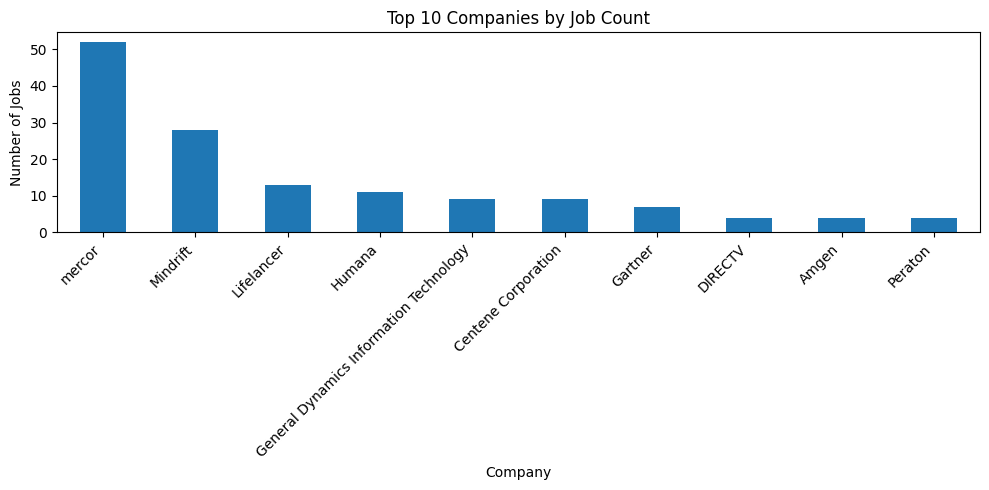

In [28]:
#Top Companies Visualization
top_companies.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Companies by Job Count")
plt.xlabel("Company")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [29]:
#Employment Type Distribution
employment_types = df["employment_type"].value_counts()

print("Employment Type Distribution:")
print(employment_types)


Employment Type Distribution:
employment_type
Full Time     389
Contractor     74
Part Time      24
Intern          8
Other           3
Temporary       2
Name: count, dtype: int64


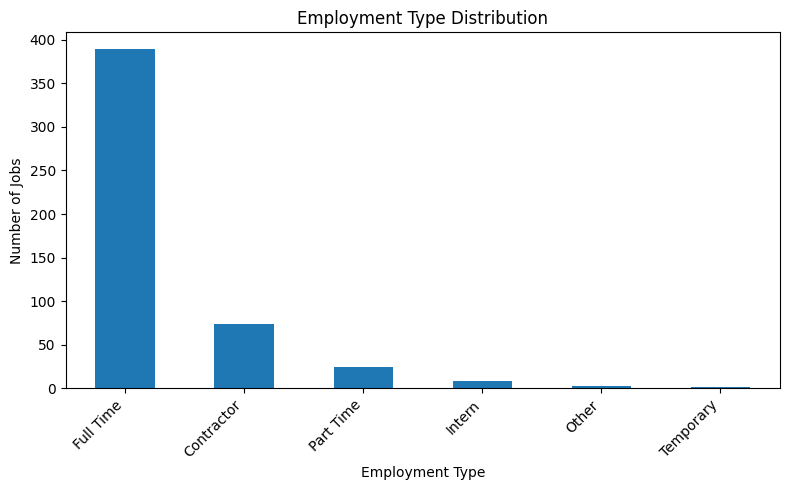

In [30]:
#Employment Type Visualization
employment_types.plot(kind="bar", figsize=(8, 5))

plt.title("Employment Type Distribution")
plt.xlabel("Employment Type")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [31]:
#Job Listings by Seniority
seniority = df["seniority"].value_counts().head(10)

print("Top Seniority Levels:")
print(seniority)


Top Seniority Levels:
seniority
Senior                    206
Mid-level                 157
Entry-level                36
Director                   35
Manager                    28
Entry-level, Mid-level     13
Manager, Senior             8
Executive                   7
Senior, Manager             4
Director, Executive         3
Name: count, dtype: int64


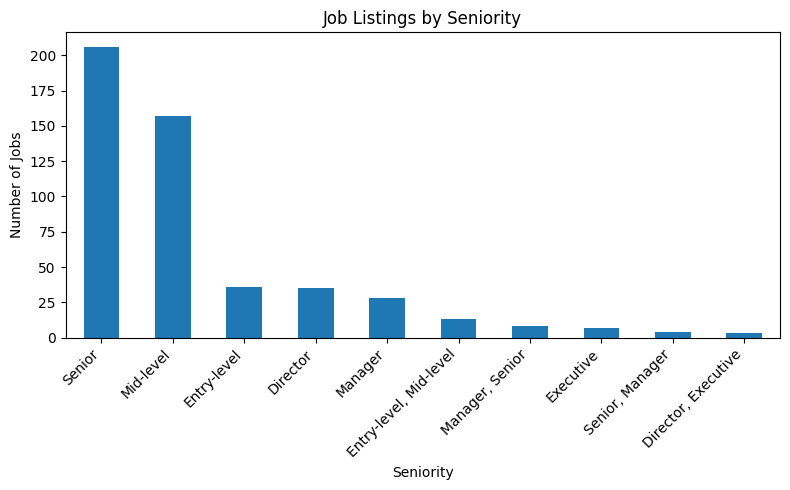

In [32]:
#Seniority Visualization
seniority.plot(kind="bar", figsize=(8, 5))

plt.title("Job Listings by Seniority")
plt.xlabel("Seniority")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [33]:
#Annual Salary Analysis by Currency
salary_df = df.dropna(
    subset=["min_salary", "max_salary"]
).copy()

salary_df = salary_df[
    salary_df["salary_period"].fillna("").str.lower() == "annual"
].copy()

salary_df["average_salary"] = (
    salary_df["min_salary"] + salary_df["max_salary"]
) / 2

print("Annual Salary Analysis by Currency:")

for currency in salary_df["currency"].dropna().unique():
    currency_df = salary_df[salary_df["currency"] == currency]

    print(f"\n{currency} Salary Statistics:")
    print(currency_df["average_salary"].describe())

Annual Salary Analysis by Currency:

USD Salary Statistics:
count       175.000000
mean     139926.780543
std       53708.333221
min       37500.000000
25%      101875.000000
50%      135000.000000
75%      170000.000000
max      330000.000000
Name: average_salary, dtype: float64

EUR Salary Statistics:
count        3.000000
mean     33350.000000
std      53393.562346
min       1950.000000
25%       2525.000000
50%       3100.000000
75%      49050.000000
max      95000.000000
Name: average_salary, dtype: float64

CAD Salary Statistics:
count         6.000000
mean     100741.666667
std       74041.038733
min       60250.000000
25%       62550.000000
50%       70975.000000
75%       87125.000000
max      250000.000000
Name: average_salary, dtype: float64

INR Salary Statistics:
count          1.0
mean     1282550.0
std            NaN
min      1282550.0
25%      1282550.0
50%      1282550.0
75%      1282550.0
max      1282550.0
Name: average_salary, dtype: float64

GBP Salary Statistics:


In [34]:
#Top 5 Highest-Paying Jobs by Currency
for currency in salary_df["currency"].dropna().unique():

    currency_df = salary_df[
        salary_df["currency"] == currency
    ]

    top_salary_jobs = (
        currency_df
        .sort_values("average_salary", ascending=False)
        [["title", "company", "average_salary", "currency", "salary_period"]]
        .head(5)
    )

    print(f"\nTop 5 Highest-Paying {currency} Jobs:")
    print(top_salary_jobs.to_string(index=False))
    


Top 5 Highest-Paying USD Jobs:
                                                                       title         company  average_salary currency salary_period
                                              Enterprise Sales Director - US         Sprinto        330000.0      USD        annual
Clinical Development Director, Early Development – Inflammation/Rare Disease           Amgen        323281.0      USD        annual
                                                          Principal Engineer        Motional        285000.0      USD        annual
                            Medical Director – Cardiology – Evicore - Remote The Cigna Group        277050.0      USD        annual
                      Finance Functional Lead - Insurance Associate Director       Accenture        276200.0      USD        annual

Top 5 Highest-Paying EUR Jobs:
                                                   title                                company  average_salary currency salary_period
         

In [35]:
#Top 10 Job Categories
categories = (
    df["categories"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

print("Top 10 Job Categories:")
print(categories)


Top 10 Job Categories:
categories
Sales                   30
Business-Development    23
Account-Management      22
Software-Engineer       19
Data-Engineering        15
B2B-Sales               15
Operations              13
Enterprise-Sales        12
Clinical-Research       11
Finance                 11
Name: count, dtype: int64


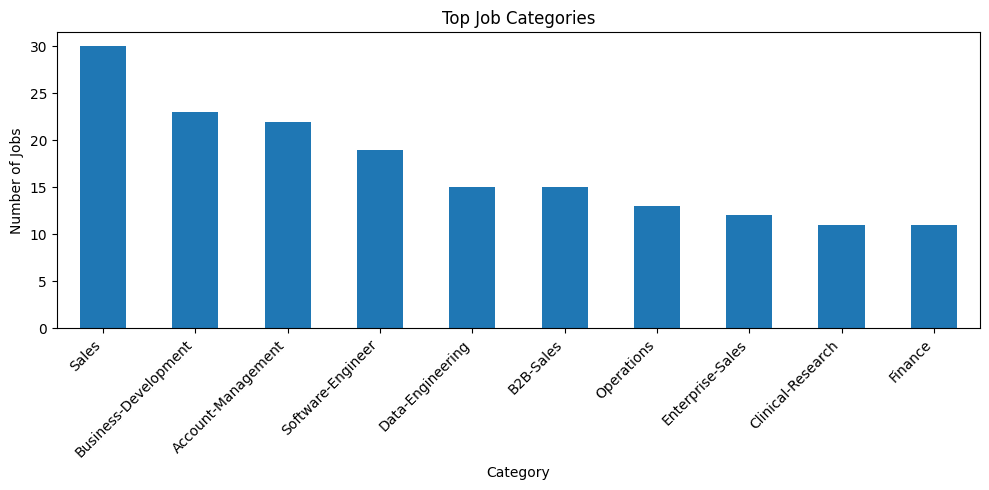

In [36]:
#Job Category Visualization
categories.plot(kind="bar", figsize=(10, 5))

plt.title("Top Job Categories")
plt.xlabel("Category")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Key Findings

The dataset contains 500 remote job listings collected from the Himalayas public Jobs API.

Key observations:

- Full-time positions make up the majority of the collected listings.
- Senior and mid-level roles account for most of the job postings.
- Mercor has the highest number of listings in the collected dataset.
- Sales, Business Development, Account Management, and Software Engineering are among the most common job categories.
- Salary information is available for a subset of listings and is analyzed separately by currency.
- The analysis demonstrates an end-to-end workflow from job data collection to storage, analysis, and visualization.